# 11 · Calibração do fundo com os 20 jogos · Cover Shadow Value (CSV)

Fase 8g do CRISP-DM (D41). Calibra-se só a parte de **fundo** do modelo do passe (`p_fundo = Π_d (1 − p_fora)`, todos os defesas incluindo o guarda-redes, tempo de interceção de Spearman/Shaw sem orientação nem bloqueio pelo corpo) com os 20 jogos abertos da SkillCorner (tracking a 10 fps e eventos; sem pose). Velocidade da bola fixa em 15 m/s. Os critérios foram fixados na D41 antes de calcular; aplicam-se à letra. Só números.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from footy.paths import output_dir

pd.options.display.float_format = "{:.4f}".format
pd.options.display.width = 200
with open(output_dir("cover_shadow") / "calibracao_20_jogos.json", encoding="utf-8") as f:
    R = json.load(f)
P, S = R["principal"], R["secundario"]
print("tempo de cálculo (s):", round(R["tempo_s"]))

tempo de cálculo (s): 11392


## 1. Passes por jogo

Passes de `player_possession` com `end_type == "pass"`; fora de jogo e resultados sem `successful`/`unsuccessful` ficam de fora; rasteiros pela D37 (`high_pass` não verdadeiro, ≤ 35 m medidos no tracking); frame de tracking do passe (`frame_end`). Principal: `pass_outcome`. Secundário: «cortado» = falhou e a posse seguinte é da equipa que defendia e começa a menos de 5 m da linha, antes do recetor; os falhados que não cumprem ficam de fora.

In [2]:
f = pd.DataFrame(R["funis"]).T
f.index = f.index.astype(int)
f = f.rename(columns={"passes": "passes (total)", "fora_de_jogo": "fora de jogo", "com_resultado": "successful/unsuccessful", "pelo_ar": "pelo ar",
                      "sem_recetor_visado": "sem recetor visado", "com_posicoes": "com posições", "mais_de_35_m": "> 35 m", "rasteiros": "rasteiros (principal)",
                      "cortados": "cortados", "secundario": "secundário (n)"})
display(f.drop(columns=["taxa_sucesso"]).astype(int))
print("total rasteiros (principal):", int(f["rasteiros (principal)"].sum()), "| cortados:", int(f["cortados"].sum()), "| secundário (n):", int(f["secundário (n)"].sum()))
print(f"taxa de sucesso (principal): {P['taxa_sucesso']:.4f} | taxa de não cortado (secundário): {S['taxa_sucesso']:.4f}")

,passes (total),fora de jogo,successful/unsuccessful,pelo ar,sem recetor visado,com posições,> 35 m,rasteiros (principal),cortados,secundário (n)
1874553,837,2,835,47,0,786,28,758,11,659
1886347,852,2,850,42,0,808,17,791,9,699
1899585,741,4,737,59,1,676,16,660,17,562
1925299,912,5,907,53,0,854,26,828,11,731
1927964,996,2,994,35,0,959,17,942,10,875
1953632,865,4,861,59,0,798,23,775,8,703
1959846,815,2,813,54,0,758,14,744,13,639
1986691,766,4,762,43,0,719,18,701,8,622
1996435,878,4,874,42,0,831,25,806,14,702
1996436,660,2,658,53,0,604,15,589,12,485


total rasteiros (principal): 14584 | cortados: 239 | secundário (n): 12627
taxa de sucesso (principal): 0.8494 | taxa de não cortado (secundário): 0.9811


## 2. Resultado principal (`pass_outcome`)

### 2.1 Parâmetros: ajuste com todos os jogos e por dobra (um jogo de fora)

In [3]:
def parametros(r):
    a = r["ajuste_total"]
    t = pd.DataFrame({"literatura": r["parametros_literatura"], "todos os jogos": a["parametros"], "erro-padrão": {k: (v if v is not None else np.nan) for k, v in a["erro_padrao"].items()}})
    display(t)
    print("log-verosimilhança (todos):", a["log_verosimilhanca"], "| parâmetros no limite:", a["no_limite"])
    d = pd.DataFrame(r["parametros_por_dobra"]).T
    d.index.name = "jogo de fora"
    rel = (d / pd.Series(a["parametros"]) - 1) * 100
    display(pd.concat({"valor": d, "desvio ao ajuste total (%)": rel}, axis=1))
    return d
dobras_p = parametros(P)

,literatura,todos os jogos,erro-padrão
tempo_reacao,0.7000,0.0503,0.0003
velocidade_defesa,5.0000,2.0002,0.0106
incerteza_tempo,0.4500,0.7373,0.0107


log-verosimilhança (todos): -4808.302704134163 | parâmetros no limite: ['tempo_reacao', 'velocidade_defesa']


valor                                   desvio ao ajuste total (%)                                  
             tempo_reacao velocidade_defesa incerteza_tempo               tempo_reacao velocidade_defesa incerteza_tempo
jogo de fora                                                                                                            
1874553            0.0528            2.0000          0.7412                     5.0114           -0.0079          0.5309
1886347            0.0500            2.0000          0.7382                    -0.6103           -0.0079          0.1267
1899585            0.0778            2.0260          0.6992                    54.5236            1.2913         -5.1635
1925299            0.0500            2.0000          0.7187                    -0.6255           -0.0079         -2.5191
1927964            0.0510            2.0000          0.7377                     1.2890           -0.0079          0.0585
1953632            0.0500            2.0000          0.7419                    -0.5892           -0.0079          0.6258
1959846            0.0919            2.0000          0.7805                    82.6386           -0.0079          5.8538
1986691            0.0501            2.0000          0.7396                    -0.4267           -0.0078          0.3084
1996435            0.0500            2.0000          0.7398                    -0.6135           -0.0079          0.3325
1996436            0.0535            2.0000          0.7337                     6.2726           -0.0079         -0.4837
2006229            0.0957            2.0000          0.7275                    90.2095           -0.0079         -1.3282
2006363            0.0541            2.0000          0.7387                     7.5029           -0.0079          0.1930
2007448            0.0907            2.0000          0.7810                    80.3551           -0.0079          5.9222
2007721            0.0529            2.0000          0.7334                     5.2013           -0.0079         -0.5264
2010085            0.0578            2.0000          0.7211                    14.8493           -0.0079         -2.1991
2011166            0.0503            2.0000          0.7349                    -0.1186           -0.0079         -0.3333
2013725            0.0503            2.0000          0.7360                    -0.0834           -0.0079         -0.1729
2015213            0.0500            2.0000          0.7321                    -0.5899           -0.0079         -0.7124
2016236            0.0506            2.0000          0.7302                     0.6262           -0.0079         -0.9668
2017461            0.0535            2.0000          0.7409                     6.2981           -0.0076          0.4918

### 2.2 Por jogo (jogo fora da amostra, ajuste com os outros 19): log-loss

In [4]:
def por_jogo(r):
    t = pd.DataFrame(r["por_jogo"]).set_index("jogo")
    t["modelo − base"] = t["log_loss_modelo"] - t["log_loss_taxa_base"]
    display(t.rename(columns={"taxa_sucesso": "taxa", "log_loss_modelo": "modelo", "log_loss_taxa_base": "taxa base",
                              "log_loss_literatura": "literatura", "log_loss_logistico": "logístico"})[
        ["passes", "taxa", "modelo", "taxa base", "literatura", "logístico", "modelo − base"]])
    display(pd.DataFrame(r["metricas_juntas"]).T)
por_jogo(P)

,passes,taxa,modelo,taxa base,literatura,logístico,modelo − base
jogo,,,,,,,
1874553,758,0.8549,0.2884,0.4143,0.3028,0.3022,-0.1259
1886347,791,0.8723,0.3093,0.3843,0.3242,0.2964,-0.0751
1899585,660,0.8258,0.3550,0.4649,0.4012,0.3448,-0.1099
1925299,828,0.8696,0.2976,0.3891,0.2994,0.3008,-0.0915
1927964,942,0.9183,0.2063,0.3072,0.2570,0.2052,-0.1009
1953632,775,0.8968,0.2210,0.3428,0.2427,0.2516,-0.1218
1959846,744,0.8414,0.3661,0.4376,0.3808,0.3393,-0.0715
1986691,701,0.8759,0.3018,0.3782,0.3567,0.2753,-0.0764
1996435,806,0.8536,0.3519,0.4165,0.3843,0.3471,-0.0646


,n,log_loss,brier,ece
modelo,14584.0000,0.3299,0.0991,0.0656
literatura,14584.0000,0.3572,0.1040,0.0499
taxa_base,14584.0000,0.4242,0.1280,0.0292
logistico,14584.0000,0.3288,0.0997,0.0168


### 2.3 Curva de calibração (previsões fora da amostra das 20 dobras, decis)

decil,0,1,2,3,4,5,6,7,8,9
n,1459.0000,1458.0000,1458.0000,1459.0000,1458.0000,1458.0000,1459.0000,1458.0000,1458.0000,1459.0000
previsto,0.1564,0.4920,0.6812,0.8062,0.8894,0.9432,0.9766,0.9937,0.9992,1.0000
observado,0.3537,0.6783,0.7997,0.8739,0.9259,0.9307,0.9698,0.9801,0.9877,0.9945


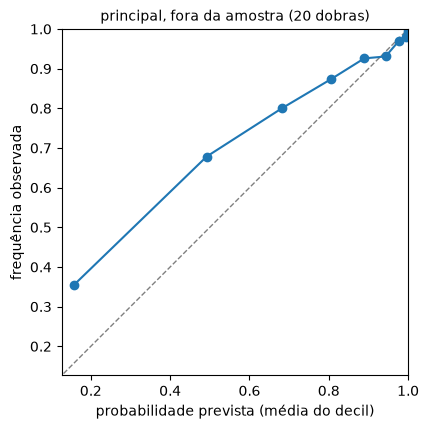

In [5]:
def curva(r, titulo):
    t = pd.DataFrame(r["curva_de_calibracao"])
    display(t.set_index("decil").T)
    _, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.plot([0, 1], [0, 1], color="grey", lw=1, ls="--")
    ax.plot(t["previsto"], t["observado"], marker="o")
    ax.set_xlabel("probabilidade prevista (média do decil)")
    ax.set_ylabel("frequência observada")
    ax.set_title(titulo, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xlim(min(t["previsto"].min(), t["observado"].min()) - 0.03, 1.0)
    ax.set_ylim(min(t["previsto"].min(), t["observado"].min()) - 0.03, 1.0)
    plt.show()
curva(P, "principal, fora da amostra (20 dobras)")

### 2.4 Critérios da D41 (aplicação mecânica da regra)

In [6]:
def mostrar_criterios(r):
    k = r["criterios"]
    c1, c2, c3 = k["criterio_1_bate_a_taxa_base"], k["criterio_2_parametros_estaveis"], k["criterio_3_calibracao"]
    sim = lambda b: "cumpre" if b else "não cumpre"
    print(f"1. Bate a taxa base: {c1['jogos_a_bater_a_base']}/{c1['n_jogos']} jogos (mínimo 16); melhoria média {c1['melhoria_media']:.5f} -> {sim(c1['cumpre'])}")
    print(f"2. Parâmetros estáveis: dobras com parâmetro no limite {c2['dobras_com_parametro_no_limite']}; dobras com algum parâmetro fora de ±20 %: {c2['dobras_fora_de_20_pct']}; "
          f"desvio relativo máximo {({n: round(v, 3) for n, v in c2['desvio_relativo_maximo'].items()})} -> {sim(c2['cumpre'])}")
    print(f"3. Calibração: ECE = {c3['ece']:.4f} (máximo 0,03) -> {sim(c3['cumpre'])}")
    print("Veredicto (regra da D41):", k["veredicto"])
mostrar_criterios(P)

1. Bate a taxa base: 20/20 jogos (mínimo 16); melhoria média 0.09526 -> cumpre
2. Parâmetros estáveis: dobras com parâmetro no limite 19; dobras com algum parâmetro fora de ±20 %: 4; desvio relativo máximo {'tempo_reacao': 0.902, 'velocidade_defesa': 0.013, 'incerteza_tempo': 0.059} -> não cumpre
3. Calibração: ECE = 0.0656 (máximo 0,03) -> não cumpre
Veredicto (regra da D41): não calibrável com estes dados


## 3. Resultado secundário (descritivo): «cortado»

Alvo: 1 = não cortado (successful, ou falhado sem corte à linha de acordo com a regra acima não entra). Mesmas dobras e mesmas contas; os critérios calculam-se apenas para registo (a D41 aplica-os só ao resultado principal).

In [7]:
dobras_s = parametros(S)

,literatura,todos os jogos,erro-padrão
tempo_reacao,0.7000,2.0000,0.0000
velocidade_defesa,5.0000,6.5503,0.5517
incerteza_tempo,0.4500,0.6906,0.0212


log-verosimilhança (todos): -1062.5890158121524 | parâmetros no limite: ['tempo_reacao']


valor                                   desvio ao ajuste total (%)                                  
             tempo_reacao velocidade_defesa incerteza_tempo               tempo_reacao velocidade_defesa incerteza_tempo
jogo de fora                                                                                                            
1874553            2.0000            6.4549          0.6955                    -0.0000           -1.4564          0.7026
1886347            2.0000            6.7548          0.6870                    -0.0000            3.1224         -0.5227
1899585            2.0000            6.3218          0.6942                    -0.0000           -3.4887          0.5174
1925299            2.0000            6.6031          0.6909                    -0.0000            0.8063          0.0451
1927964            2.0000            6.5037          0.6958                    -0.0000           -0.7105          0.7449
1953632            2.0000            6.5086          0.6952                    -0.0000           -0.6360          0.6683
1959846            2.0000            6.5842          0.6897                    -0.0000            0.5180         -0.1355
1986691            2.0000            6.4668          0.6951                    -0.0000           -1.2748          0.6506
1996435            2.0000            6.5644          0.6905                    -0.0000            0.2157         -0.0124
1996436            2.0000            6.4853          0.6925                    -0.0000           -0.9927          0.2762
2006229            2.0000            6.6008          0.6839                    -0.0000            0.7717         -0.9768
2006363            2.0000            6.5311          0.6904                    -0.0000           -0.2934         -0.0385
2007448            2.0000            6.5790          0.6925                    -0.0000            0.4384          0.2670
2007721            2.0000            6.7048          0.6877                    -0.0000            2.3598         -0.4266
2010085            2.0000            6.6146          0.6895                    -0.0000            0.9825         -0.1634
2011166            2.0000            6.4300          0.6937                    -0.0000           -1.8364          0.4522
2013725            2.0000            6.5105          0.6888                    -0.0000           -0.6069         -0.2686
2015213            2.0000            6.5051          0.6920                    -0.0000           -0.6898          0.1948
2016236            2.0000            6.5443          0.6910                    -0.0000           -0.0905          0.0530
2017461            2.0000            6.7304          0.6769                    -0.0000            2.7504         -1.9928

,passes,taxa,modelo,taxa base,literatura,logístico,modelo − base
jogo,,,,,,,
1874553,659,0.9833,0.0699,0.0850,0.1556,0.0717,-0.0151
1886347,699,0.9871,0.0698,0.0701,0.2064,0.0662,-0.0003
1899585,562,0.9698,0.1252,0.1389,0.2348,0.1213,-0.0137
1925299,731,0.9850,0.0681,0.0786,0.1539,0.0711,-0.0104
1927964,875,0.9886,0.0499,0.0645,0.1607,0.0466,-0.0146
1953632,703,0.9886,0.0478,0.0642,0.1241,0.0482,-0.0164
1959846,639,0.9797,0.0859,0.0994,0.2212,0.0826,-0.0135
1986691,622,0.9871,0.0676,0.0700,0.2188,0.0535,-0.0024
1996435,702,0.9801,0.0821,0.0978,0.2020,0.0805,-0.0157


,n,log_loss,brier,ece
modelo,12627.0000,0.0843,0.0178,0.0068
literatura,12627.0000,0.1905,0.0511,0.0953
taxa_base,12627.0000,0.0940,0.0186,0.0057
logistico,12627.0000,0.0794,0.0177,0.0021


decil,0,1,2,3,4,5,6,7,8,9
n,1263.0000,1263.0000,1262.0000,1263.0000,1263.0000,1262.0000,1263.0000,1262.0000,1263.0000,1263.0000
previsto,0.8929,0.9646,0.9772,0.9835,0.9875,0.9906,0.9932,0.9955,0.9975,0.9992
observado,0.9272,0.9707,0.9842,0.9794,0.9826,0.9889,0.9881,0.9968,0.9937,0.9992


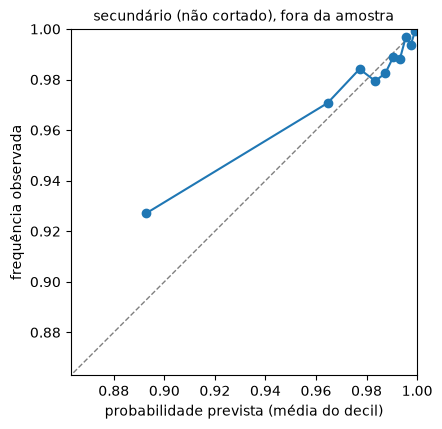

1. Bate a taxa base: 16/20 jogos (mínimo 16); melhoria média 0.00996 -> cumpre
2. Parâmetros estáveis: dobras com parâmetro no limite 20; dobras com algum parâmetro fora de ±20 %: 0; desvio relativo máximo {'tempo_reacao': 0.0, 'velocidade_defesa': 0.035, 'incerteza_tempo': 0.02} -> não cumpre
3. Calibração: ECE = 0.0068 (máximo 0,03) -> cumpre
Veredicto (regra da D41): não calibrável com estes dados


In [8]:
por_jogo(S)
curva(S, "secundário (não cortado), fora da amostra")
mostrar_criterios(S)

## 4. Referências na mesma tabela (resultado principal, 20 dobras, log-loss médio por passe das previsões juntas)

Taxa base (média do treino), parâmetros da literatura (0,7 s, 5 m/s, 0,45 s), logístico simples (comprimento + distância do defesa mais próximo à linha) e modelo calibrado.

In [9]:
ref = pd.DataFrame({"principal": {m: v["log_loss"] for m, v in P["metricas_juntas"].items()},
                    "secundário": {m: v["log_loss"] for m, v in S["metricas_juntas"].items()}})
ref2 = pd.DataFrame({"ECE principal": {m: v["ece"] for m, v in P["metricas_juntas"].items()}, "ECE secundário": {m: v["ece"] for m, v in S["metricas_juntas"].items()},
                     "Brier principal": {m: v["brier"] for m, v in P["metricas_juntas"].items()}, "Brier secundário": {m: v["brier"] for m, v in S["metricas_juntas"].items()}})
display(pd.concat([ref.add_prefix("log-loss "), ref2], axis=1))
print("Veredicto da D41 (resultado principal):", P["criterios"]["veredicto"])

,log-loss principal,log-loss secundário,ECE principal,ECE secundário,Brier principal,Brier secundário
modelo,0.3299,0.0843,0.0656,0.0068,0.0991,0.0178
literatura,0.3572,0.1905,0.0499,0.0953,0.1040,0.0511
taxa_base,0.4242,0.0940,0.0292,0.0057,0.1280,0.0186
logistico,0.3288,0.0794,0.0168,0.0021,0.0997,0.0177


Veredicto da D41 (resultado principal): não calibrável com estes dados


## Notas de implementação

- `calibracao_fundo.py` (D41). Dados preparados por `uv run python projects/cover_shadow/calibracao_fundo.py preparar`, calibração por `... calibrar`.
- A velocidade dos defesas é a de `metrica.velocidade` (diferença central sobre 0,4 s, tracking a 10 fps; passos acima de 12 m/s anulados). O guarda-redes conta como defesa.
- Os jogos 1925299 e 1996435 também têm pose; aqui usa-se só tracking, como nos outros 18.
- Limites da busca: tempo de reação [0,05; 2,0] s, velocidade [2; 9] m/s, σ [0,05; 2,0] s; «no limite» = a menos de 0,01. Nelder-Mead com três pontos iniciais; erro-padrão pelo Hessiano numérico.
- Não se recalcularam a v3.1 nem a v4.